In [1]:
import sys,json,os,warnings
warnings.filterwarnings('ignore')
sys.path.insert(0,'../scripts')
import numpy as np,pandas as pd,matplotlib.pyplot as plt,matplotlib.dates as mdates
from common import *
ACC="#20808D";MUTE="#9a9a94";INK="#2b2b2b";BAD="#C8452F"
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':10,'axes.edgecolor':MUTE,'axes.labelcolor':INK,'xtick.color':INK,'ytick.color':INK,'axes.titlesize':11.5,'axes.titleweight':'bold','axes.titlelocation':'left','figure.dpi':130,'savefig.bbox':'tight','lines.linewidth':2})
M='../outputs/metrics.json'
def save_metrics(k,v):
    d=json.load(open(M)) if os.path.exists(M) else {}
    d[k]=v;json.dump(d,open(M,'w'),indent=1,default=float)
pd.set_option('display.width',160)


# 3. Robustness
Each row changes one thing against the headline run: CS, 6 treated states, 17 controls, Jan 2019 to Dec 2023. Effect is the mean over months 0 to 12.

In [2]:
p=load();pn=p[p.state!='CHANDIGARH']
gm=lambda d:d.dropna(subset=['gt']).groupby('state')['gt'].first().astype(int).to_dict()
c=sorted(p[p.group=='control'].state.unique());g=gm(pn)
def run(lbl,d=pn,gg=g,cc=c,**k):
    A=[]
    for y in ['share','logodds']:
        W=wide(d,y);s,a,_=event_study(W,gg,cc,**k);A+= [a,s.loc[-12:-2].mean()]
    return dict(check=lbl,points=A[0],pre_points=A[1],logodds=A[2],pre_logodds=A[3])
R=[run('Headline')]
R.append(run('Base is mean of last 6 months, not month -1',base_k=6))
for k_ in g:
    R.append(run(f'Drop {k_.title()}',gg={a:b for a,b in g.items() if a!=k_}))
R.append(run('Drop Karnataka, Tamil Nadu from controls',cc=[x for x in c if x not in('KARNATAKA','TAMIL NADU')]))
big=p[p.year==2019].groupby('state').regs_2w.sum();cb=[x for x in c if big[x]>=300000]
R.append(run(f'Controls over 3 lakh 2W a year ({len(cb)})',cc=cb))
a=load(alt_dates=True);a=a[a.state!='CHANDIGARH'];R.append(run('Chhattisgarh start Aug 2022',d=a,gg=gm(a)))
o=load(override={'CHHATTISGARH':'2022-04'});o=o[o.state!='CHANDIGARH'];R.append(run('Chhattisgarh start Apr 2022, as first planned',d=o,gg=gm(o)))
gc=pn.copy();gc.loc[(gc.state=='GOA')&(gc.date>'2022-07-01'),['share','logodds']]=np.nan;R.append(run('Goa cut at end of first scheme, Jul 2022',d=gc))
b=load(treat=('paid','paper'));b=b[b.state!='CHANDIGARH'];R.append(run('Add 5 on-paper states (11), months 0 to 10',d=b,gg=gm(b),cc=c,lags=10))
e=load(treat=('paper',));R.append(run('On-paper states only (5), months 0 to 10',d=e,gg=gm(e),cc=c,lags=10))
Wb=wide(pn[pn.state.isin(list(g)+cb)],'share');_x,ab,_y=event_study(Wb,g,cb);Rb=rand_inf(Wb,g,cb,n=1999);pb=(np.abs(Rb[:,0])>=abs(ab)).mean();print('large-control RI p',pb);save_metrics('large_controls',{'att':ab,'ri_p':pb,'n':len(cb),'names':cb})
T=pd.DataFrame(R).round(3);T.to_csv('../outputs/tables/robustness.csv',index=False);print(T.to_string(index=False))
save_metrics('robust',T.set_index('check').to_dict('index'))

large-control RI p 0.4447223611805903
                                        check  points  pre_points  logodds  pre_logodds
                                     Headline   1.061      -0.887   -0.026       -0.344
  Base is mean of last 6 months, not month -1   1.718      -0.230    0.259       -0.058
                            Drop Chhattisgarh   1.407      -0.513    0.009       -0.297
                                   Drop Delhi   1.183      -1.055   -0.050       -0.338
                                     Drop Goa   0.431      -0.753   -0.020       -0.350
                             Drop Maharashtra   0.872      -1.015   -0.093       -0.447
                                  Drop Odisha   1.004      -0.966   -0.056       -0.297
                           Drop Uttar Pradesh   1.467      -1.019    0.054       -0.333
     Drop Karnataka, Tamil Nadu from controls   1.193      -0.964   -0.034       -0.318
           Controls over 3 lakh 2W a year (9)   0.684      -0.660   -0.177       -

## Imputation estimator, with and without state trends
Fits state and month effects on untreated cells only, then predicts what treated states would have done. State trends absorb any steady gap in growth.

In [3]:
rows=[]
for y in ['share','logodds']:
  for tr in [False,True]:
    a_,st=imp_att(pn,y,tr);Rr=rand_imp(pn,y,tr,n=499);rows.append(dict(outcome=y,state_trends=tr,att=a_,ri_p=(np.abs(Rr)>=abs(a_)).mean()))
I=pd.DataFrame(rows).round(3);I.to_csv('../outputs/tables/imputation.csv',index=False);print(I);save_metrics('impute',I.to_dict('records'))

   outcome  state_trends    att   ri_p
0    share         False  1.989  0.046
1    share          True  1.707  0.004
2  logodds         False  0.558  0.172
3  logodds          True  0.077  0.868


## Estimator grid
The same question through each estimator, with randomisation p-values, so no single choice carries the verdict. Pre-trend uses months -12 to -7, which do not overlap the six-month base.

In [4]:
rows=[]
for y in ['share','logodds']:
    W=wide(pn,y)
    for lbl,k_,ix in [('CS, base month -1',1,0),('CS, base last 6 months',6,0),('CS, all post months',1,2)]:
        s_,a_,b_=event_study(W,g,c,base_k=k_);v=a_ if ix==0 else b_;Rr=rand_inf(W,g,c,n=999,base_k=k_)
        rows.append(dict(outcome=y,spec=lbl,att=v,ri_p=(np.abs(Rr[:,ix])>=abs(v)).mean(),pre_m12_m7=s_.loc[-12:-7].mean(),pre_m6_m2=s_.loc[-6:-2].mean()))
G=pd.DataFrame(rows).round(3);G.to_csv('../outputs/tables/estimator_grid.csv',index=False);print(G.to_string(index=False));save_metrics('grid',G.to_dict('records'))

outcome                   spec    att  ri_p  pre_m12_m7  pre_m6_m2
  share      CS, base month -1  1.061 0.132      -0.969     -0.788
  share CS, base last 6 months  1.718 0.010      -0.312     -0.131
  share    CS, all post months  2.455 0.021      -0.969     -0.788
logodds      CS, base month -1 -0.026 0.920      -0.344     -0.344
logodds CS, base last 6 months  0.259 0.400      -0.059     -0.057
logodds    CS, all post months  0.018 0.955      -0.344     -0.344


## Placebo dates
Every treated state is moved 12 months early, and data from its real start onward is deleted. A real design shows nothing here.

In [5]:
def placebo(y):
    d=pn.copy();d=d[~(d.g.notna()&(d.date>=d.g))]
    gg={k:v-12 for k,v in g.items() if v-12>=7};W=wide(d,y)
    s,a,_=event_study(W,gg,c,leads=6,lags=11);R_=rand_inf(W,gg,c,n=1999,leads=6,lags=11)
    return a,(np.abs(R_[:,0])>=abs(a)).mean(),np.percentile(R_[:,0],[2.5,97.5])
P={y:placebo(y) for y in ['share','logodds']};print(P)
save_metrics('placebo',{y:{'att':P[y][0],'ri_p':P[y][1]} for y in P})

{'share': (np.float64(0.31168999346357124), np.float64(0.295647823911956), array([-0.48792383,  0.57833856])), 'logodds': (np.float64(0.49180019140214104), np.float64(0.2051025512756378), array([-0.85255791,  0.72616028]))}


## Placebo outcome
The subsidy should not move non-electric registrations much. A large shift would point to a demand shock.

In [6]:
W=wide(pn,'log_nonev');s,a,_=event_study(W,g,c);R_=rand_inf(W,g,c,n=1999);pv=(np.abs(R_[:,0])>=abs(a)).mean();print(a,pv);save_metrics('placebo_outcome',{'att':a,'ri_p':pv})

0.060568957421840694 0.7053526763381691


## Randomisation distribution
The actual dates are dealt to random states 1,999 times.

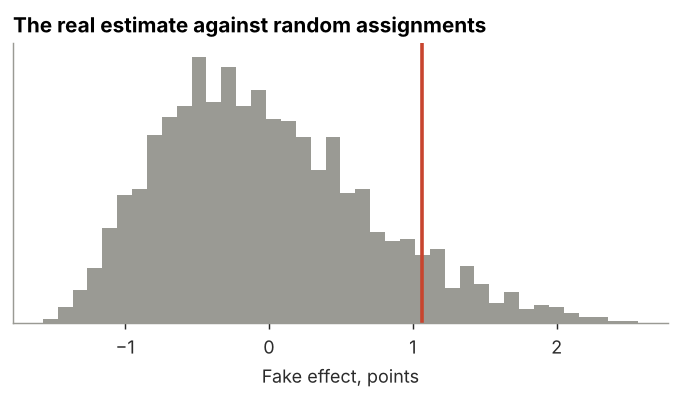

0.0895447723861931 0.13656828414207103


In [7]:
W=wide(pn,'share');_,a,_b=event_study(W,g,c);RR=rand_inf(W,g,c,n=1999)
sm=(RR[:,0]>=a).mean();two=(np.abs(RR[:,0])>=abs(a)).mean()
fig,ax=plt.subplots(figsize=(6.5,2.8));ax.hist(RR[:,0],bins=40,color=MUTE);ax.axvline(a,color=BAD);ax.set_xlabel('Fake effect, points');ax.set_title('The real estimate against random assignments');ax.set_yticks([]);plt.savefig('../outputs/charts/randomisation.png');plt.show()
print(sm,two);save_metrics('ri',{'two_sided':two})

## Does the gap survive?
Descriptive only: the window is extended to October 2026. Several subsidies ended and other states began, so this is not a causal estimate.

In [8]:
P=load(end='2026-10-01');P=P[P.state!='CHANDIGARH']
s=P.groupby([P.date.dt.year,'state']).agg(g=('group','first'),e=('regs_e2w','sum'),n=('regs_2w','sum'));s['sh']=100*s.e/s.n
t=s.reset_index().groupby(['date','g']).sh.median().unstack().round(2);print(t);t.to_csv('../outputs/tables/median_share_by_year.csv');save_metrics('median_2026',t.loc[2026].to_dict())

g     control   paid
date                
2019     0.07   0.15
2020     0.07   0.17
2021     0.88   1.47
2022     2.54   6.12
2023     2.16   7.94
2024     3.47   7.88
2025     3.52   8.18
2026     5.13  11.71


## Cost per additional EV
The plan set this to run only if the effect survives. It does not clearly survive, so this is a conditional range. It takes each state's own estimate at face value. Spending has a low and a high case because the Maharashtra early-bird add-on may or may not stack, its base subsidy stopped sometime in 2022, and Goa's scheme had a unit cap. Battery size of 3 kWh is an assumption. Chhattisgarh is left out: its terms have no clear two-wheeler cap.

In [9]:
bs=pd.read_csv('../outputs/tables/by_state.csv').set_index('state').att_points
rows=[];win={k:pn[(pn.state==k)&(pn['t']>=v)&(pn['t']<=v+12)] for k,v in g.items()}
mh=win['MAHARASHTRA'];mh_a=mh[mh.date<='2022-03-01'].regs_e2w.sum();mh_b=mh[mh.date>'2022-03-01'].regs_e2w.sum()
goa=win['GOA'];goa_live=goa[goa.date<='2022-07-01'].regs_e2w.sum()
low={'DELHI':win['DELHI'].regs_e2w.sum()*15000,'MAHARASHTRA':mh_a*10000,'ODISHA':win['ODISHA'].regs_e2w.sum()*5000,'GOA':5.5e7,'UTTAR PRADESH':win['UTTAR PRADESH'].regs_e2w.sum()*5000}
high={**low,'MAHARASHTRA':mh_a*25000+mh_b*10000,'GOA':min(goa_live,3000)*30000}
C=pd.DataFrame({'spend_low':low,'spend_high':high});C['all2w']=[win[k].regs_2w.sum() for k in C.index];C['e2w']=[win[k].regs_e2w.sum() for k in C.index];C['att']=bs.reindex(C.index)
C['extra']=C.att/100*C.all2w;C['extra_floored']=C.extra.clip(lower=0);C.round(1).to_csv('../outputs/tables/cost_inputs.csv');print(C)
lo,hi=C.spend_low.sum(),C.spend_high.sum();ef,eu=C.extra_floored.sum(),C.extra.sum()
out=dict(spend_low_cr=lo/1e7,spend_high_cr=hi/1e7,extra_floored=ef,extra_unfloored=eu,rs_low=lo/ef,rs_high=(hi/eu if eu>0 else None),avg_low=lo/C.e2w.sum(),avg_high=hi/C.e2w.sum(),additional_share_floored=ef/C.e2w.sum(),additional_share_unfloored=eu/C.e2w.sum(),goa_live_ev=int(goa_live))
print(out);save_metrics('cost',out)

                 spend_low  spend_high    all2w    e2w   att       extra  extra_floored
DELHI           57375000.0    57375000   309677   3825  0.45   1393.5465      1393.5465
MAHARASHTRA    403890000.0  1335805000  1661483  72997  2.00  33229.6600     33229.6600
ODISHA          99370000.0    99370000   505544  19874  1.34   6774.2896      6774.2896
GOA             55000000.0    78690000    52231   5147  4.21   2198.9251      2198.9251
UTTAR PRADESH  188010000.0   188010000  2576479  37602 -0.97 -24991.8463         0.0000
{'spend_low_cr': np.float64(80.3645), 'spend_high_cr': np.float64(175.925), 'extra_floored': np.float64(43596.421200000004), 'extra_unfloored': np.float64(18604.574900000003), 'rs_low': np.float64(18433.737859198405), 'rs_high': np.float64(94560.07511356789), 'avg_low': np.float64(5763.168274229984), 'avg_high': np.float64(12616.0851948797), 'additional_share_floored': np.float64(0.3126424124206677), 'additional_share_unfloored': np.float64(0.1334187306823479), 'goa_l